In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [2]:
from google.colab import files
uploaded = files.upload()
dataset = pd.read_csv("uber.csv")

Saving uber.csv to uber.csv


In [3]:
dataset.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [4]:
dataset.shape

(200000, 9)

In [5]:
dataset.dtypes

,0
Unnamed: 0,int64
key,object
fare_amount,float64
pickup_datetime,object
pickup_longitude,float64
pickup_latitude,float64
dropoff_longitude,float64
dropoff_latitude,float64
passenger_count,int64


In [6]:
dataset.isnull().sum()

,0
Unnamed: 0,0
key,0
fare_amount,0
pickup_datetime,0
pickup_longitude,0
pickup_latitude,0
dropoff_longitude,1
dropoff_latitude,1
passenger_count,0


## Preprocess the dataset

In [7]:
dataset.drop(
    columns=["Unnamed: 0", "key"],
    errors="ignore",
    inplace=True
)

dataset.dropna(inplace=True)

dataset["pickup_datetime"] = pd.to_datetime(
    dataset["pickup_datetime"],
    errors="coerce",
    utc=True
)
dataset.dropna(subset=["pickup_datetime"], inplace=True)

dataset = dataset[
    (dataset["fare_amount"] > 0) &
    (dataset["passenger_count"] > 0) &
    (dataset["passenger_count"] <= 6) &
    (dataset["pickup_latitude"].between(-90, 90)) &
    (dataset["dropoff_latitude"].between(-90, 90)) &
    (dataset["pickup_longitude"].between(-180, 180)) &
    (dataset["dropoff_longitude"].between(-180, 180))
].copy()

dataset.shape

(199256, 7)

In [8]:
dataset["hour"] = dataset["pickup_datetime"].dt.hour
dataset["day"] = dataset["pickup_datetime"].dt.day
dataset["month"] = dataset["pickup_datetime"].dt.month
dataset["year"] = dataset["pickup_datetime"].dt.year
dataset["day_of_week"] = dataset["pickup_datetime"].dt.dayofweek

In [9]:
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = (
        np.sin(dlat / 2) ** 2 +
        np.cos(lat1) * np.cos(lat2) *
        np.sin(dlon / 2) ** 2
    )
    return 6371 * 2 * np.arcsin(np.sqrt(a))

dataset["distance"] = haversine(
    dataset["pickup_latitude"],
    dataset["pickup_longitude"],
    dataset["dropoff_latitude"],
    dataset["dropoff_longitude"]
)

dataset = dataset[
    (dataset["distance"] > 0) &
    (dataset["distance"] < 100)
].copy()

dataset.head()

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,day_of_week,distance
0,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,2015,3,1.683323
1,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,2009,4,2.457590
2,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,2009,0,5.036377
3,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,2009,4,1.661683
4,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,2014,3,4.475450


## Identify and remove outliers (IQR method)

In [10]:
Q1 = dataset["fare_amount"].quantile(0.25)
Q3 = dataset["fare_amount"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = dataset[
    (dataset["fare_amount"] < lower) |
    (dataset["fare_amount"] > upper)
]

outliers.shape

(16540, 13)

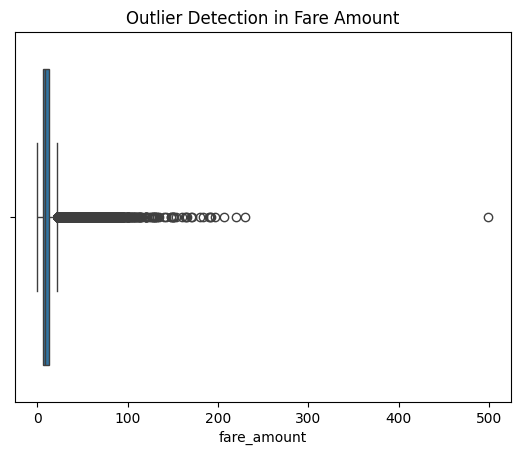

In [11]:
sns.boxplot(x=dataset["fare_amount"])
plt.title("Outlier Detection in Fare Amount")
plt.show()

In [12]:
dataset = dataset[
    (dataset["fare_amount"] >= lower) &
    (dataset["fare_amount"] <= upper)
].copy()

dataset.shape

(176651, 13)

## Correlation analysis

In [13]:
correlation = dataset.select_dtypes(include=["number"]).corr()
correlation["fare_amount"].sort_values(ascending=False)

,fare_amount
fare_amount,1.000000
distance,0.723498
year,0.135745
month,0.026705
day_of_week,0.020356
passenger_count,0.013017
day,0.006575
dropoff_longitude,0.002047
pickup_longitude,0.001204
pickup_latitude,-0.002014


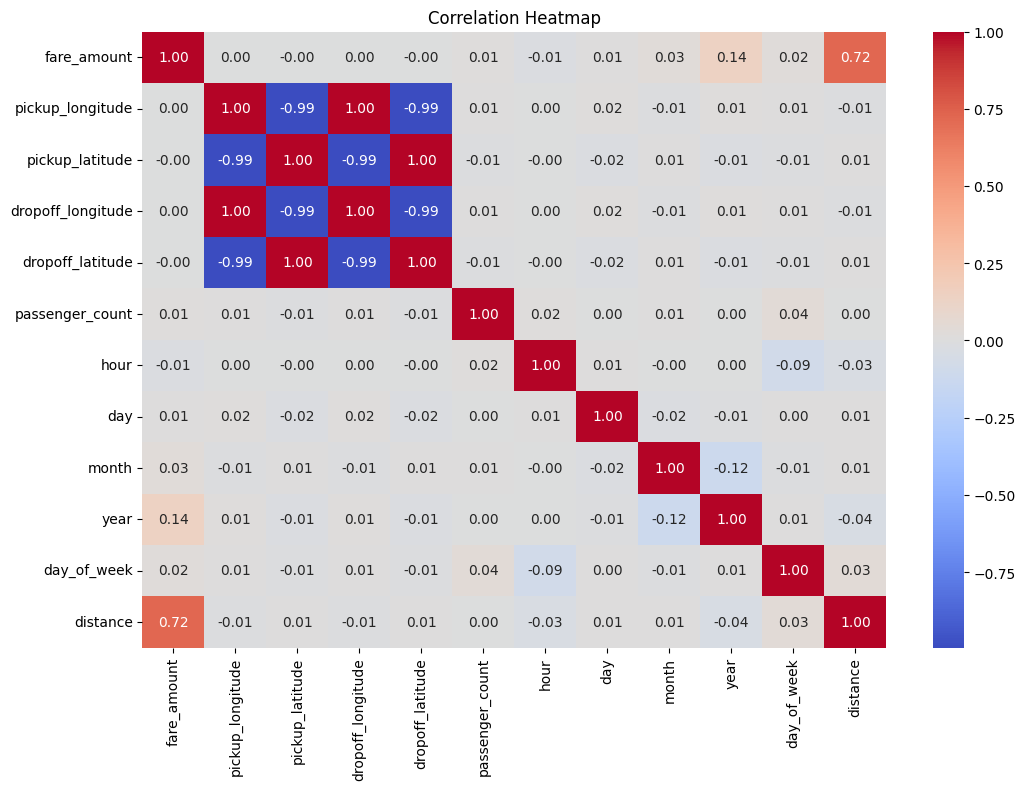

In [14]:
plt.figure(figsize=(12, 8))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

## Prepare data and split

In [15]:
features = [
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude",
    "passenger_count", "hour", "day", "month",
    "year", "day_of_week", "distance"
]

X = dataset[features]
y = dataset["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Linear Regression

In [16]:
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

In [17]:
r2_lr = r2_score(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
mae_lr = mean_absolute_error(y_test, y_pred_lr)

pd.Series({
    "R2 Score": r2_lr,
    "RMSE": rmse_lr,
    "MAE": mae_lr
})

,0
R2 Score,0.617254
RMSE,2.554108
MAE,1.796168


## Random Forest Regression

In [25]:
rf = RandomForestRegressor(
    n_estimators=20,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

In [26]:
r2_rf = r2_score(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
mae_rf = mean_absolute_error(y_test, y_pred_rf)

pd.Series({
    "R2 Score": r2_rf,
    "RMSE": rmse_rf,
    "MAE": mae_rf
})

,0
R2 Score,0.771432
RMSE,1.973748
MAE,1.363462


## Compare models

In [27]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest Regression"],
    "R2 Score": [r2_lr, r2_rf],
    "RMSE": [rmse_lr, rmse_rf],
    "MAE": [mae_lr, mae_rf]
})

results

,Model,R2 Score,RMSE,MAE
0,Linear Regression,0.617254,2.554108,1.796168
1,Random Forest Regression,0.771432,1.973748,1.363462


In [30]:
if r2_rf > r2_lr and rmse_rf < rmse_lr:
    "Random Forest Regression performs better"
elif r2_lr > r2_rf and rmse_lr < rmse_rf:
    "Linear Regression performs better"
else:
    "The metrics show mixed performance"

## Predict fare for a sample ride

In [29]:
new_ride = pd.DataFrame([{
    "pickup_longitude": -73.985,
    "pickup_latitude": 40.748,
    "dropoff_longitude": -73.985,
    "dropoff_latitude": 40.758,
    "passenger_count": 1,
    "hour": 14,
    "day": 2,
    "month": 11,
    "year": 2026,
    "day_of_week": 0,
    "distance": 1.1
}])

# Using the successfully fitted Linear Regression model
# since the Random Forest model training was interrupted.
lr.predict(new_ride)

array([12.29672889])